In [1]:
import numpy as np
import sklearn
import pandas as pd
from itertools import cycle
from collections import Counter
from sklearn.preprocessing import StandardScaler, label_binarize, LabelBinarizer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import *
from sklearn.gaussian_process.kernels import RBF
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

# Preliminary Analysis of Data

Do not do cross validation

Each line in the dataset specifies the following:
1. It is a summary of the results obtained from a 3x3 grid from a particular region. Each cell in the grid indicates a pixel
2. The region has data in 4 channels (each pixel is described by 4 values).
3. Each value is obtained from an image, hence ranges from 0 to 255.
4. For this grid, there is a classification given : for the land cover ranging from 1 to 7 (exception - no class 6 in the dataset)

# Preparing the Dataset in proper format

Run only once

In [7]:
train_data_path = "data/sat.trn"
test_data_path  = "data/sat.tst"

In [8]:
with open(train_data_path, "r") as f:
    train_data = f.readlines()
train_data = np.array([line.split(' ') for line in train_data]).astype(np.int16)
train_dataset = pd.DataFrame(train_data) 

In [9]:
with open(test_data_path, "r") as f:
    test_data = f.readlines()
test_data = np.array([line.split(' ') for line in test_data]).astype(np.int16)
test_dataset = pd.DataFrame(test_data)

In [10]:
cols = [f'X{i}' for i in range(len(train_data[0, :-1]))] + ['Y']
train_dataset.columns = cols
test_dataset.columns = cols

In [11]:
test_dataset

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X27,X28,X29,X30,X31,X32,X33,X34,X35,Y
0,80,102,102,79,76,102,102,79,76,102,...,87,79,107,109,87,79,107,113,87,3
1,76,102,102,79,76,102,106,83,76,102,...,87,79,107,113,87,79,103,104,83,3
2,80,98,106,79,76,94,102,76,76,94,...,79,79,95,100,79,79,95,96,75,4
3,76,94,102,76,76,94,102,76,76,94,...,79,79,95,96,75,79,95,100,75,4
4,76,94,102,76,76,94,102,76,76,89,...,75,79,95,100,75,75,95,100,79,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,60,83,96,85,64,87,100,88,64,83,...,92,66,87,108,89,63,83,104,85,1
1996,64,79,100,85,56,71,96,85,56,68,...,85,66,83,100,85,63,83,100,81,1
1997,56,68,91,81,56,64,91,81,53,64,...,81,59,87,96,81,63,83,92,74,5
1998,56,68,87,74,60,71,91,81,60,64,...,74,59,83,92,74,59,83,92,70,5


In [12]:
train_dataset.to_csv('data/train.csv', index=False)
test_dataset.to_csv('data/test.csv', index=False)

# EDA

In [2]:
train_dataset = pd.read_csv('data/train.csv')
test_dataset  = pd.read_csv('data/test.csv')

In [3]:
train_dataset

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X27,X28,X29,X30,X31,X32,X33,X34,X35,Y
0,92,115,120,94,84,102,106,79,84,102,...,104,88,121,128,100,84,107,113,87,3
1,84,102,106,79,84,102,102,83,80,102,...,100,84,107,113,87,84,99,104,79,3
2,84,102,102,83,80,102,102,79,84,94,...,87,84,99,104,79,84,99,104,79,3
3,80,102,102,79,84,94,102,79,80,94,...,79,84,99,104,79,84,103,104,79,3
4,84,94,102,79,80,94,98,76,80,102,...,79,84,103,104,79,79,107,109,87,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4430,56,64,108,96,64,71,108,96,68,75,...,92,66,83,108,96,66,87,104,89,5
4431,64,71,108,96,68,75,108,96,71,87,...,96,66,87,104,89,63,87,104,89,5
4432,68,75,108,96,71,87,108,88,71,91,...,89,63,87,104,89,70,100,104,85,4
4433,71,87,108,88,71,91,100,81,76,95,...,89,70,100,104,85,70,91,104,85,4


In [4]:
test_dataset

,X0,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X27,X28,X29,X30,X31,X32,X33,X34,X35,Y
0,80,102,102,79,76,102,102,79,76,102,...,87,79,107,109,87,79,107,113,87,3
1,76,102,102,79,76,102,106,83,76,102,...,87,79,107,113,87,79,103,104,83,3
2,80,98,106,79,76,94,102,76,76,94,...,79,79,95,100,79,79,95,96,75,4
3,76,94,102,76,76,94,102,76,76,94,...,79,79,95,96,75,79,95,100,75,4
4,76,94,102,76,76,94,102,76,76,89,...,75,79,95,100,75,75,95,100,79,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,60,83,96,85,64,87,100,88,64,83,...,92,66,87,108,89,63,83,104,85,1
1996,64,79,100,85,56,71,96,85,56,68,...,85,66,83,100,85,63,83,100,81,1
1997,56,68,91,81,56,64,91,81,53,64,...,81,59,87,96,81,63,83,92,74,5
1998,56,68,87,74,60,71,91,81,60,64,...,74,59,83,92,74,59,83,92,70,5


Standardize the features

In [5]:
X_train, y_train = train_dataset.drop(columns=['Y']), train_dataset['Y']
X_train_std = StandardScaler().fit_transform(X_train)

X_test, y_test = test_dataset.drop(columns=['Y']), test_dataset['Y']
X_test_std = StandardScaler().fit_transform(X_test)

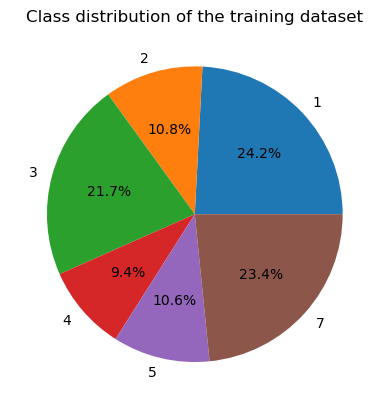

In [6]:
labels = list(set(train_dataset['Y']))
class_dist = {label : len(train_dataset[train_dataset['Y'] == label]) for label in labels}
plt.pie(x = class_dist.values(), labels=labels, autopct='%1.1f%%')
plt.title("Class distribution of the training dataset")
plt.savefig("images/class_dist_train.png")
plt.show()

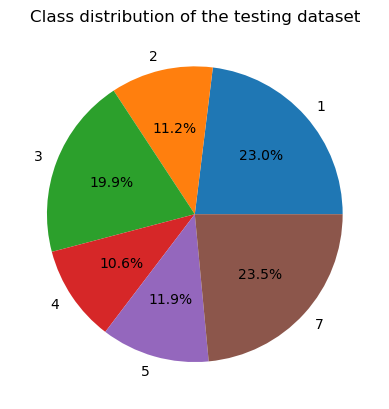

In [7]:
labels = list(set(test_dataset['Y']))
class_dist = {label : len(test_dataset[test_dataset['Y'] == label]) for label in labels}
plt.pie(x = class_dist.values(), labels=labels, autopct='%1.1f%%')
plt.title("Class distribution of the testing dataset")
plt.savefig("images/class_dist_test.png")
plt.show()

We see that both training and testing datasets have the same ratio of classes, and the class proportion of 1, 3, and 7 are same, and so is same for 2, 4 and 5. So, overall, balanced dataset

# Setup of the Machinery

Summary of each classifier:
1. K-Nearest Neigbors (KNN) : Labels the points near a labeled point,
2. Decision Tree: Iteratively Splits the data into a subspaces according to a (feature, value) pair,
3. Dummy: Random 50% classifier,
4. Logisitic: Performs Regression through a sigmoid curve,
5. Naive Bayes (Gaussian) : Assumes each point is independent from each other, generated by Gaussian dist
5. SVC: Support vector classifier,
6. Random Forest: Ensemble method involving multiple trees created independently,
7. GradBoost: Ensemble method involving sequential creation of trees with boosting,
8. AdaBoost: Ensemble method involving sequential creation of trees with boosting,
9. Gaussian Process: assuming the data is generated from a Guassian Process,
10. Multi-layer Perceptron (MLP): Neural Network,
11. Quadratic Discriminant Analysis (QDA): Classifier plotting a quadratic decision boundary

In [60]:
def report_generator(y_pred, y_test, name):
    n_classes = 7
    precision = dict()
    recall = dict()
    average_precision = dict()

    y_test_bin = label_binarize(y_test, classes=list(range(1, 8)))
    y_pred_bin = label_binarize(y_pred, classes=list(range(1, 8)))
    for i in range(1, n_classes):
        if i != 5:
            precision[i], recall[i], _ = precision_recall_curve(y_test_bin[:, i], y_pred_bin[:, i])
            average_precision[i] = average_precision_score(y_test_bin[:, i], y_pred_bin[:, i])
    precision["micro"], recall["micro"], _ = precision_recall_curve(y_test_bin.ravel(), y_pred_bin.ravel())
    average_precision["micro"] = average_precision_score(y_test_bin, y_pred_bin, average="micro")
    
    report = {
        "name": name,
        "precision": precision,
        "recall": recall,
        "avg_p": average_precision,
        # "pr_curve": precision_recall_curve(y_test, y_pred),
        "f1": f1_score(y_test, y_pred, average='weighted'),
        "confusion_matrix": confusion_matrix(y_test, y_pred),
        # "roc_curve": roc_curve(y_test, y_pred),
        # "likelihood_ratios": class_likelihood_ratios(y_test, y_pred),
        "bal_acc": balanced_accuracy_score(y_test, y_pred),
        "mcc": matthews_corrcoef(y_test, y_pred),
        "accuracy": accuracy_score(y_test, y_pred),
        # "roc_auc": roc_auc_score(y_test_bin, y_pred_bin, average='micro', multi_class='ovr')
    }

    return report

In [61]:
def comparison_metrics():
    # Plot of Report generated using sklearn
    metrics = list(cul_report[list(cul_report.keys())[0]].keys())

    fig, axs = plt.subplots(4, 2, figsize = (25, 15))
    i, j = 0, 0
    color_palette = [
        '#1A1A1A',  # Onyx
        '#D55E00',  # Vermillion
        '#0072B2',  # Cerulean Blue
        '#009E73',  # Shamrock Green
        '#56B4E9',  # Sky Blue
        '#E69F00',  # Amber
        '#CC79A7',  # Pale Violet
        '#F0E442',  # Canary Yellow
        '#999999'   # Gray
    ]
    for metric in metrics:
        print(metric)
        ax = axs[i, j]
        vals = [cul_report[report][metric] for report in cul_report]
        ax.bar(x=list(cul_report.keys()), height=vals, color=color_palette)
        ax.tick_params(axis='x', labelrotation=45)
        ax.set_ylabel(f"{metric.capitalize()} Value")
        # if not all(isinstance(i, tuple) for i in vals):
        #     m = 1.1 if max(vals) > 0.7 else max(vals) + 0.05
        #     n = 0 if min(vals) < 0.3 else min(vals) - 0.05
        #     ax.set_ylim(n, m)
        ax.set_title(f"{metric} value across different methods")
        # for q in range(len(vals)):
        #     ax.text(q, vals[q], np.round(vals[q], 2), ha='center')  # Aligning text at center
        j += 1
        if j == 2:
            i += 1
            j = 0

    fig.suptitle("Comparison of different methods", fontsize='xx-large')
    plt.savefig("images/total_cul_report.png")
    plt.subplots_adjust(wspace=0.1, hspace=1.5)
    plt.show()

Explain how the One-vs-Rest (OvR) approach is  used to generate ROC curves and calculate the Area Under the Curve (AUC) in a multi-class setting:<br>


In the case of multiclass classification, a notion of TPR or FPR while plotting the ROC curve is obtained only after binarizing the output. This can be done in 2 different ways:
1. The One-vs-Rest scheme compares each class against all the others (assumed as one):<br>
This strategy consists of computing a ROC curve per each of the n_classes. In each step, a given class is regarded as the positive class and the remaining classes are regarded as the negative class as a bulk. We can one-hot encode the target in a OvR fashion where a ```n_samples``` is converted to a ```(n_sample, n_classes)```

In [ ]:
def plot_roc_curve(test_y, y_prob, name):
    n_classes = 7
    y_true_bin = label_binarize(test_y, classes=list(range(1, n_classes + 1)))
    y_true_bin[:, 5] = y_true_bin[:, 6]
    y_true_bin = y_true_bin[:, :6]
    n_classes -= 1

    fpr = dict()
    tpr = dict()
    roc_auc = dict()

    # all 
    for i in range(n_classes):
        fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
        roc_auc[i] = auc(fpr[i], tpr[i])
    
    # micro
    fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), y_prob.ravel())
    roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

    # macro
    all_fpr = np.unique(np.concatenate([fpr[i] for i in range(n_classes)]))
    mean_tpr = np.zeros_like(all_fpr)
    for i in range(n_classes):
        mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
    mean_tpr /= n_classes
    fpr["macro"] = all_fpr
    tpr["macro"] = mean_tpr
    roc_auc["macro"] = auc(fpr["macro"], tpr["macro"])

    # micro-average
    plt.plot(fpr["micro"], tpr["micro"],
         label=f'micro-average ROC curve (AUC = {roc_auc["micro"]:.2f})',
         color='deeppink', linestyle=':', linewidth=4)

    # macro-average curve
    plt.plot(fpr["macro"], tpr["macro"],
            label=f'macro-average ROC curve (AUC = {roc_auc["macro"]:.2f})',
            color='navy', linestyle=':', linewidth=4)

    summary = {'fpr': fpr["macro"], "tpr": tpr["macro"], "auc": roc_auc["macro"]}
    # per-class curves
    colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red'])
    for i, color in zip(range(n_classes), colors):
        plt.plot(fpr[i], tpr[i], color=color, lw=2,
                label=f'ROC curve of class {i} (AUC = {roc_auc[i]:.2f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=2) # Dashed diagonal
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Multi-Class Receiver Operating Characteristic (ROC)')
    plt.legend(loc="lower right")
    plt.savefig(f"images/roc_{name}.png")
    plt.show()

    return summary

Explain why the Precision-Recall Curve (PRC) is a more suitable metric than ROC when dealing with highly imbalanced classes (addressing the conceptual importance even if the imbalance in this dataset is moderate).

In [193]:
def plot_pr_curve(test_y, y_prob, name):
    n_classes = 7
    y_true_bin = label_binarize(test_y, classes=list(range(1, n_classes + 1)))
    y_true_bin[:, 5] = y_true_bin[:, 6]
    y_true_bin = y_true_bin[:, :6]
    n_classes -= 1

    # --- Plotting Setup ---
    precision = dict()
    recall = dict()
    pr_auc = dict() # Area under the PR curve is often called Average Precision (AP)

    # 2. Calculate PR curve and Average Precision for each class
    for i in range(n_classes):
        precision[i], recall[i], _ = precision_recall_curve(y_true_bin[:, i], y_prob[:, i])
        pr_auc[i] = average_precision_score(y_true_bin[:, i], y_prob[:, i])

    # Micro
    precision["micro"], recall["micro"], _ = precision_recall_curve(y_true_bin.ravel(), y_prob.ravel())
    pr_auc["micro"] = average_precision_score(y_true_bin, y_prob, average="micro")

    # Macro
    all_recall = np.unique(np.concatenate([recall[i] for i in range(n_classes)]))
    mean_precision = np.zeros_like(all_recall)
    for i in range(n_classes):
        mean_precision += np.interp(all_recall, recall[i], precision[i])
    mean_precision /= n_classes
    recall["macro"] = all_recall
    precision["macro"] = mean_precision
    pr_auc["macro"] = pr_auc["micro"] = average_precision_score(y_true_bin, y_prob, average="macro")

    summary = {'recall': recall["macro"], "precision": precision["macro"], "auc": pr_auc["macro"]}
    # --- 4. Plot all PR curves ---
    plt.figure(figsize=(8, 6))

    # Plot micro-average curve
    plt.plot(recall["micro"], precision["micro"],
            label=f'micro-average PR curve (AP = {pr_auc["micro"]:.2f})',
            color='deeppink', linestyle=':', linewidth=4)

    # Plot macro
    plt.plot(recall["macro"], precision["macro"],
            label=f'macro-average ROC curve (AUC = {pr_auc["macro"]:.2f})',
            color='navy', linestyle=':', linewidth=4)
    
    # Plot per-class curves
    colors = cycle(['aqua', 'darkorange', 'cornflowerblue', 'green', 'red'])
    for i, color in zip(range(n_classes), colors):
        plt.plot(recall[i], precision[i], color=color, lw=2,
                label=f'PR curve of class {i} (AP = {pr_auc[i]:.2f})')

    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Recall')
    plt.ylabel('Precision')
    plt.title('Multi-Class Precision-Recall Curve')
    plt.legend(loc="lower left")
    plt.savefig(f"images/pr_{name}.png")
    plt.show()

    return summary

In [194]:
def classify(model, train_x, train_y, test_x, test_y, name):
    model = model.fit(train_x, train_y)
    pred = model.predict(test_x)
    pred_prob = model.predict_proba(test_x)

    roc_summary = plot_roc_curve(test_y, pred_prob, name)
    pr_summary  = plot_pr_curve(test_y, pred_prob, name)
    r = report_generator(pred, test_y, name)
    k = ['name', 'precision','recall','f1','bal_acc','mcc','accuracy', 'avg_p']
    new_r1 = {i: r[i] for i in k}
    new_r1['roc'] = roc_summary
    new_r1['pr'] = pr_summary
    # for i in new_r1:
    #     print(f"{i}: {new_r1[i]}")
    # # df = pd.DataFrame.from_dict(new_r1, orient='index', columns=['Score']).transpose()

    cul_report[name] = new_r1
    # total_df[name] = df

# Performing Experiments

In [195]:
classifiers = [
    KNeighborsClassifier(n_neighbors=7),  # Inherent Multiclass
    DecisionTreeClassifier(random_state=42),  # Inherent Multiclass
    DummyClassifier(),  # Inherent Multiclass
    LogisticRegression(),  # One vs the Rest
    GaussianNB(),  # Inherent Multiclass
    SVC(probability=True, random_state=42),  # One vs One
    RandomForestClassifier(random_state=42),  # Inherent Multiclass
    GradientBoostingClassifier(random_state=42),  # One vs the Rest
    AdaBoostClassifier(random_state=42),  # Inherent
    # GaussianProcessClassifier(1.0 * RBF(1.0), random_state=42, multi_class='one_vs_rest'),  # One vs the Rest
    # MLPClassifier(random_state=42),  # Inherent Multiclass
    # QuadraticDiscriminantAnalysis()  # Inherent Multiclass
]
names = [
    "KNNs",
    "Decision Tree",
    "Dummy",
    "Logisitic",
    "Naive Bayes",
    "SVC",
    "Random Forest",
    "GradBoost",
    "AdaBoost",
    # "Gaussian Process",
    # "MLP",
    # "QDA"
]
cul_report = dict()
total_df = dict()

KNNs


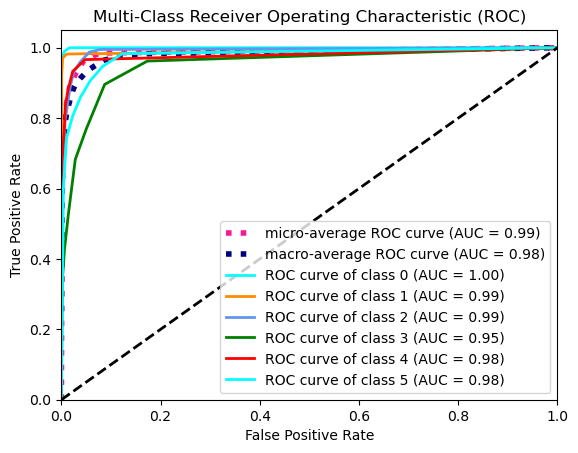

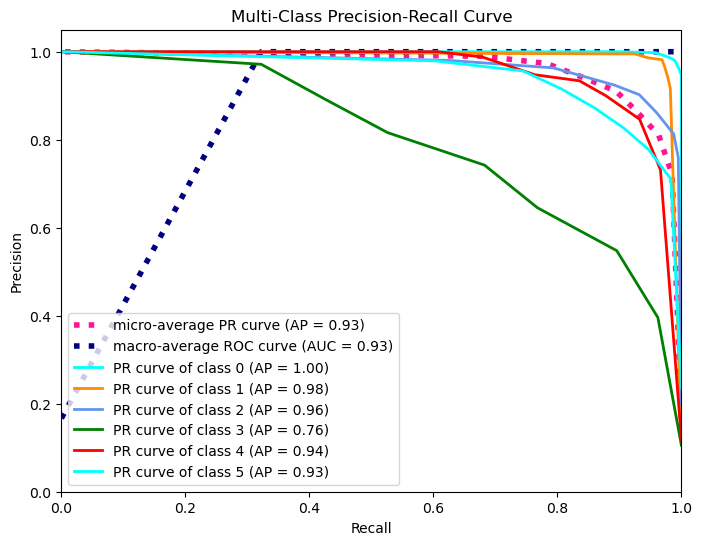



Decision Tree


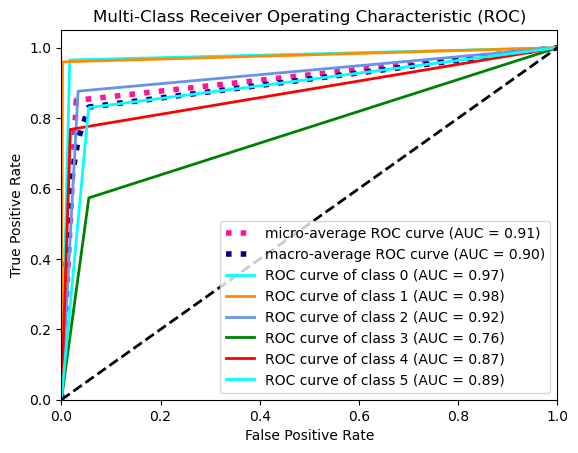

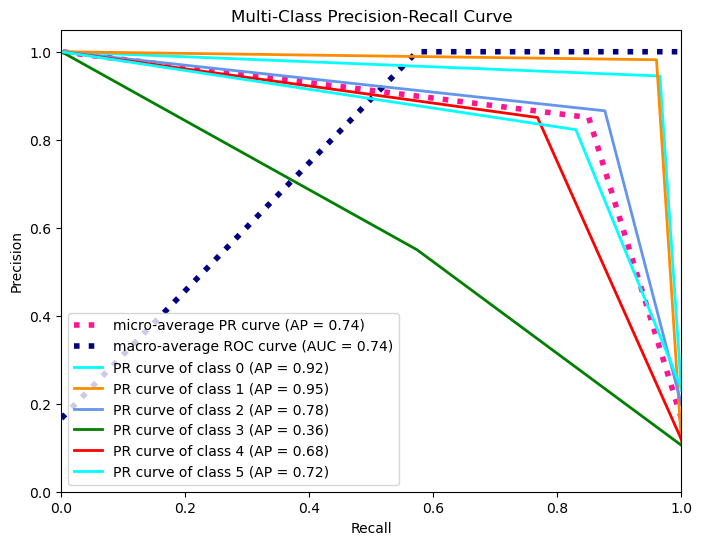



Dummy


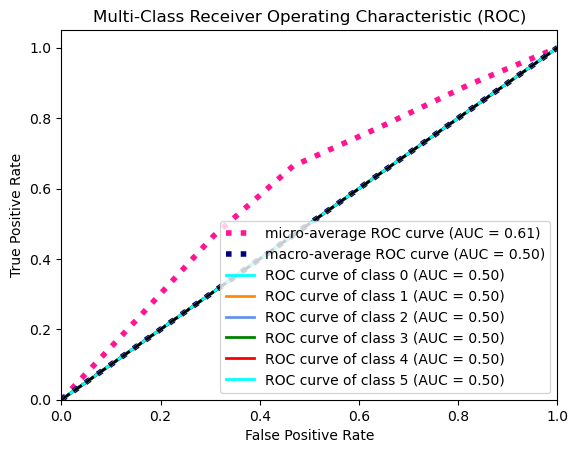

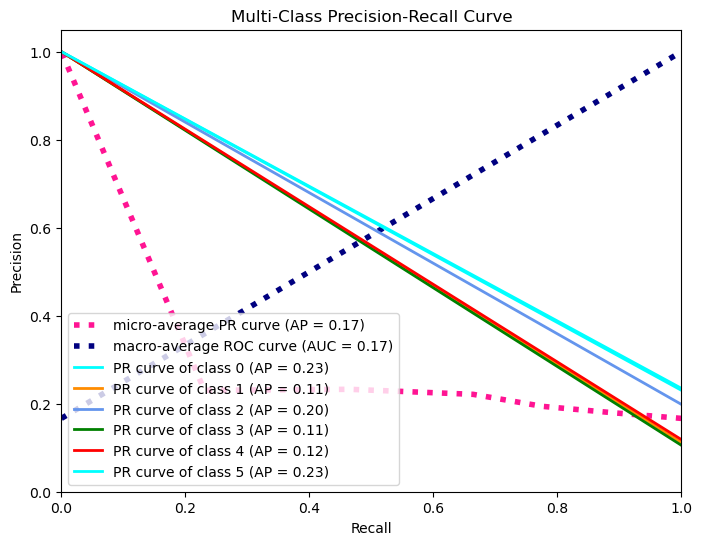



Logisitic


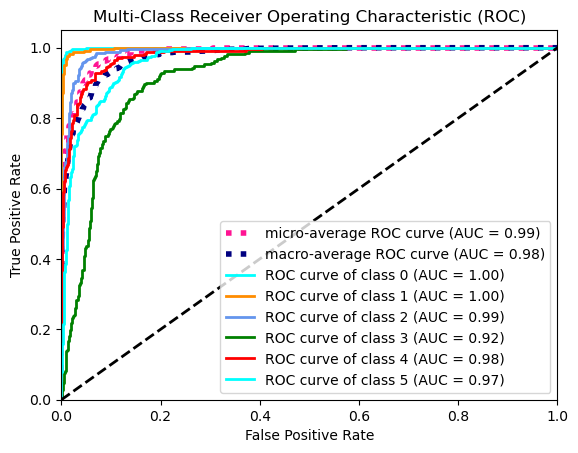

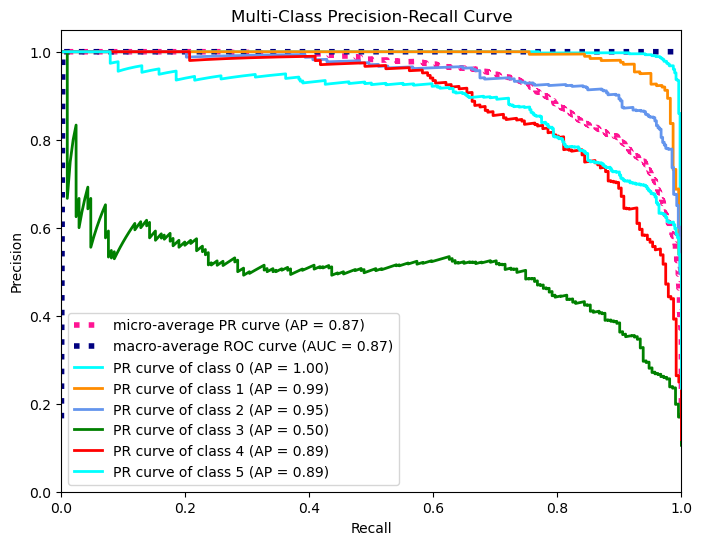



Naive Bayes


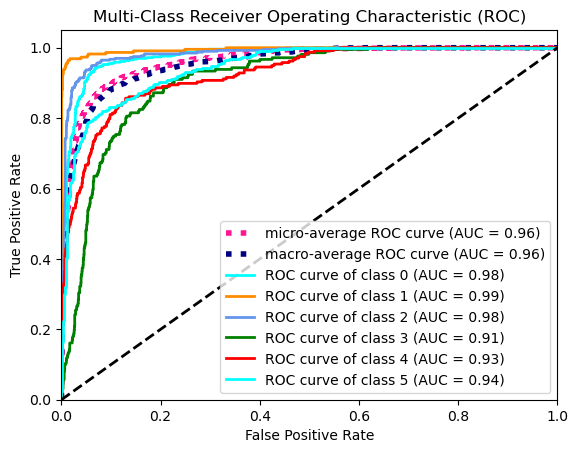

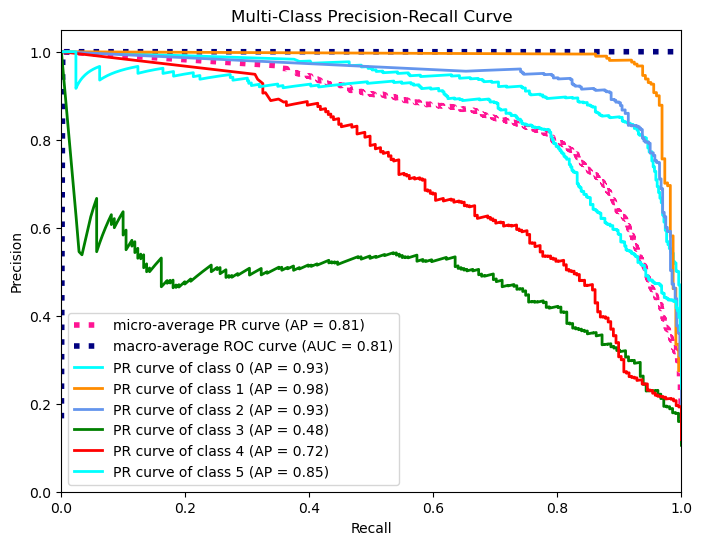



SVC


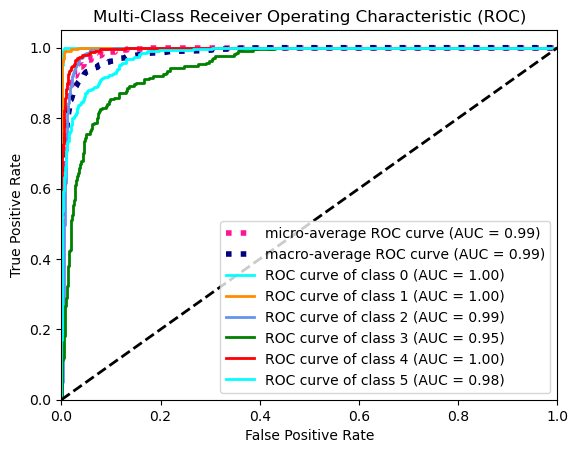

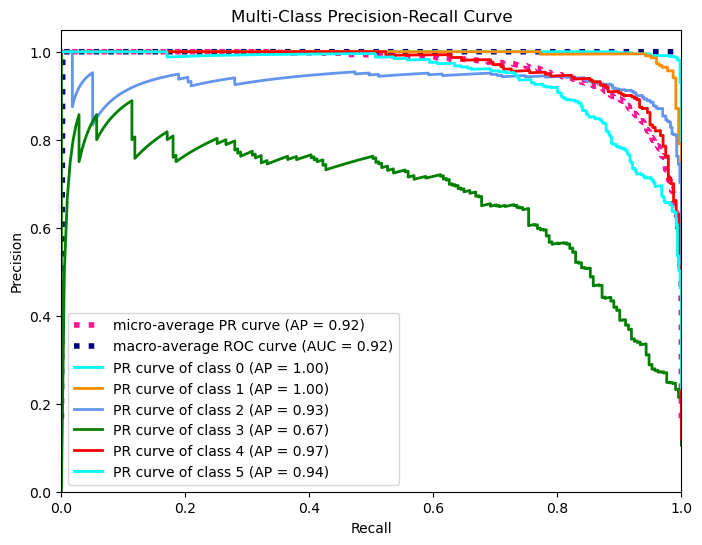



Random Forest


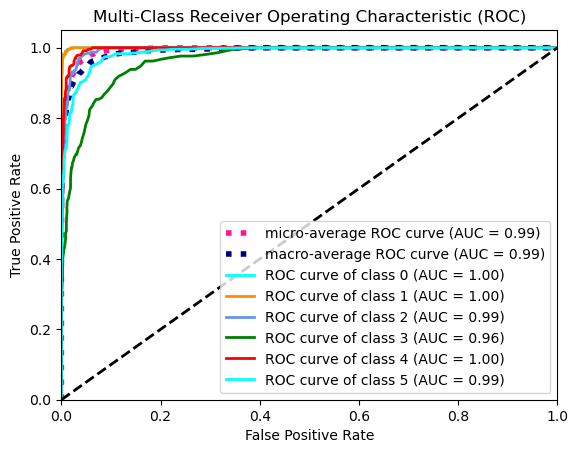

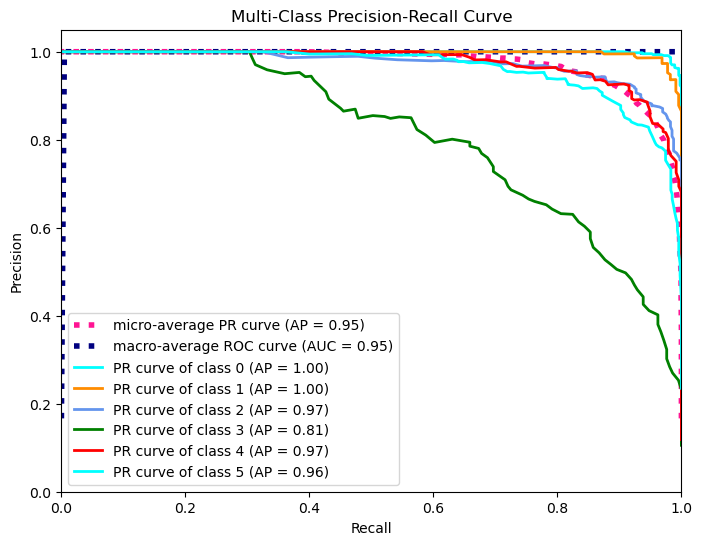



GradBoost


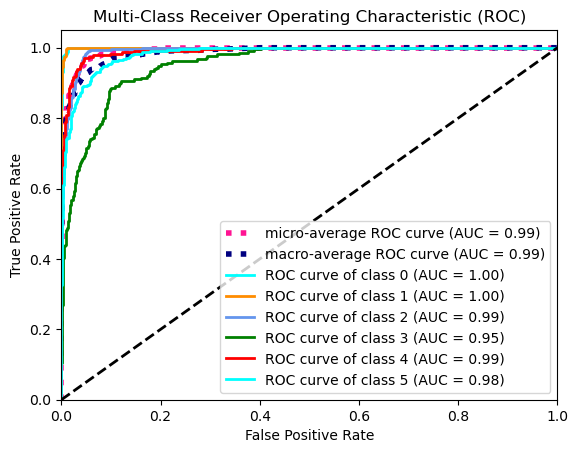

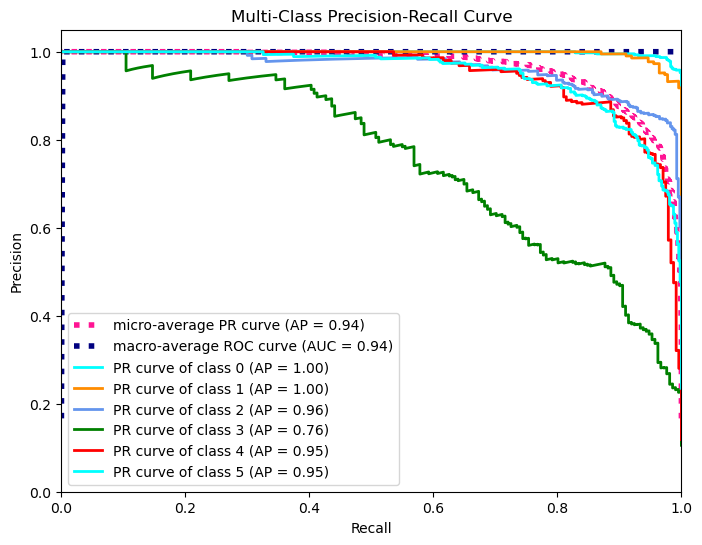



AdaBoost


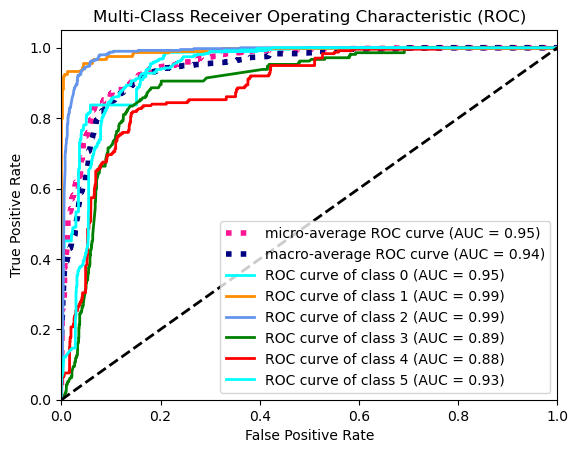

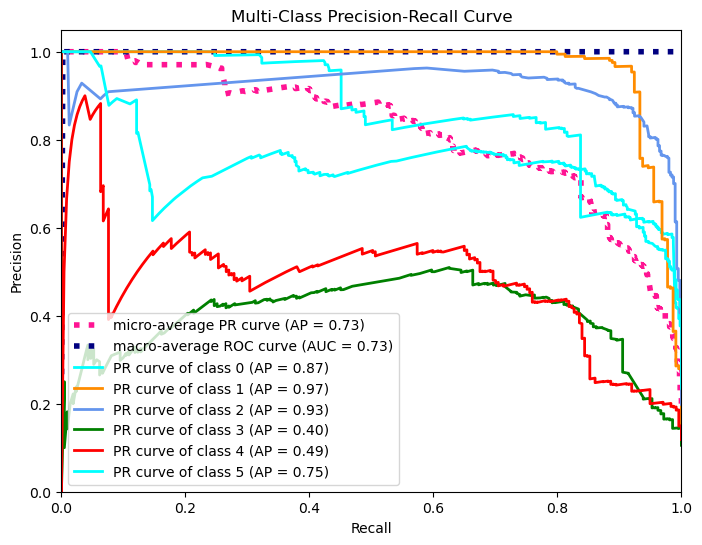

In [196]:
for name, classifier in zip(names, classifiers):
    print(name)
    classify(classifier, X_train_std, y_train, X_test_std, y_test, name)
    print("\n")

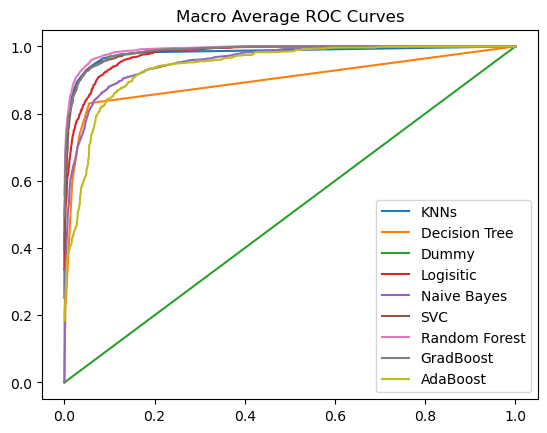

In [175]:
roc_value = [(cul_report[model]['name'], cul_report[model]['roc']) for model in cul_report]
for n in range(len(roc_value)):
    name = roc_value[n][0]
    roc = roc_value[n][1]
    plt.plot(roc["fpr"], roc["tpr"], label=name)
plt.title("Macro Average ROC Curves")
plt.legend()
plt.savefig("images/roc_macro.png")
plt.show()

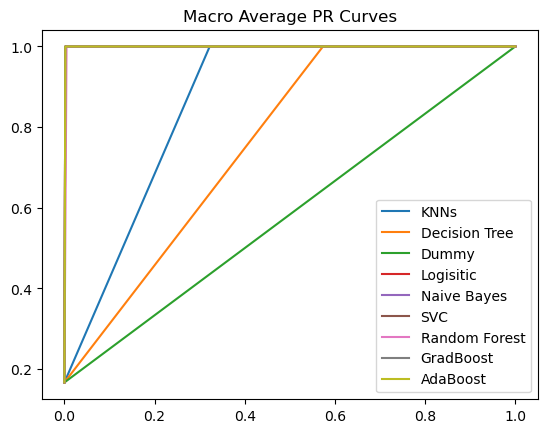

In [197]:
pr_value = [(cul_report[model]['name'], cul_report[model]['pr']) for model in cul_report]
for n in range(len(pr_value)):
    name = pr_value[n][0]
    pr = pr_value[n][1]
    plt.plot(pr["recall"], pr["precision"], label=name)
plt.title("Macro Average PR Curves")
plt.legend()
plt.savefig("images/pr_macro.png")
plt.show()

In [ ]:
comp_df = pd.concat(total_df, axis=0)

# Results

# Conclusion